# Solar PV: a half-century cost collapse and the global capacity boom

Question: How much have solar photovoltaic (PV) module costs fallen since
1975, and how has global installed solar capacity grown in response?

Data: Our World in Data (CC BY 4.0)
  - data/solar-pv-prices.csv             (Nemet 2009; Farmer & Lafond 2016; IRENA 2025)
  - data/installed-solar-pv-capacity.csv (IRENA 2026, Renewable Energy Statistics)

Run:  python solar_analysis.py        (standalone script)
      or open solar_analysis.ipynb    (the same analysis as a notebook)

Both routes reproduce the two figures saved in figures/ and print the key
statistics used in the README.

## 1. Setup

Import the libraries and define one shared chart style, so both figures look consistent.

In [1]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# Shared chart style (used by both figures)
INK      = "#182530"   # near-black for titles / strong text
BODY     = "#3D4753"   # axis labels, values
MUTED    = "#5C6674"   # secondary text
FAINT    = "#9AA4B2"   # de-emphasised text
GRID     = "#EDF1F5"   # horizontal gridlines
SPINE    = "#D8DEE6"   # axes spines
AMBER    = "#E8A33D"   # the solar accent
AMBER_DK = "#C77D0A"   # darker amber for lines / strong accents
AMBER_LT = "#F3CE94"   # soft amber for fills
WHITE    = "#FFFFFF"

plt.rcParams.update({
    "font.family": ["Helvetica Neue", "Arial", "Helvetica", "DejaVu Sans"],
    "axes.edgecolor": SPINE,
    "axes.linewidth": 0.9,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.unicode_minus": False,
    "figure.facecolor": WHITE,
    "axes.facecolor": WHITE,
    "savefig.facecolor": WHITE,
})
DPI = 200


## 2. Load the data

Both series are downloaded from Our World in Data. Each CSV covers every country plus a `World` aggregate; here we keep the world rows only.

In [2]:
price = pd.read_csv("data/solar-pv-prices.csv")
price = price[price.Entity == "World"][["Year", "Solar PV module cost"]].dropna()

cap = pd.read_csv("data/installed-solar-pv-capacity.csv")
cap = cap[cap.Entity == "World"][["Year", "Solar"]].dropna()
cap = cap[cap.Year.between(2000, 2024)]

print(f"Module price series : {int(price.Year.min())}-{int(price.Year.max())}, {len(price)} annual observations")
print(f"Capacity series     : {int(cap.Year.min())}-{int(cap.Year.max())}, {len(cap)} annual observations")
price.head()


Module price series : 1975-2024, 50 annual observations
Capacity series     : 2000-2024, 25 annual observations


,Year,Solar PV module cost
0,1975,132.375700
1,1976,99.597580
2,1977,72.661120
3,1978,51.408165
4,1979,43.195120


## 3. Key numbers

Compute the headline statistics that the README and the figures use.

In [3]:
p_first, p_last = price.iloc[0], price.iloc[-1]
price_change = (p_last["Solar PV module cost"] / p_first["Solar PV module cost"] - 1) * 100

cap_2000 = float(cap[cap.Year == 2000]["Solar"].iloc[0])
cap_2012 = float(cap[cap.Year == 2012]["Solar"].iloc[0])
cap_2022 = float(cap[cap.Year == 2022]["Solar"].iloc[0])
cap_2024 = float(cap[cap.Year == 2024]["Solar"].iloc[0])

print(f"Module price {int(p_first.Year)}: ${p_first['Solar PV module cost']:.2f}/W  ->  "
      f"{int(p_last.Year)}: ${p_last['Solar PV module cost']:.2f}/W  ({price_change:+.1f}%)")
print(f"Installed capacity {int(cap.Year.min())}: {cap_2000:.1f} GW  ->  2024: {cap_2024:,.0f} GW  "
      f"(x{cap_2024/cap_2000:,.0f})")
print(f"Milestones: {cap_2012:,.0f} GW in 2012 · {cap_2022:,.0f} GW in 2022 (first terawatt)")


Module price 1975: $132.38/W  ->  2024: $0.27/W  (-99.8%)
Installed capacity 2000: 1.2 GW  ->  2024: 1,883 GW  (x1,542)
Milestones: 103 GW in 2012 · 1,058 GW in 2022 (first terawatt)


## 4. Figure 1 — the cost collapse

The price series spans five orders of magnitude, so the y-axis is logarithmic: equal vertical distances represent equal percentage changes. Endpoint values are printed directly so the absolute size of the collapse is not lost.

saved figures/fig1_solar_cost_collapse.png


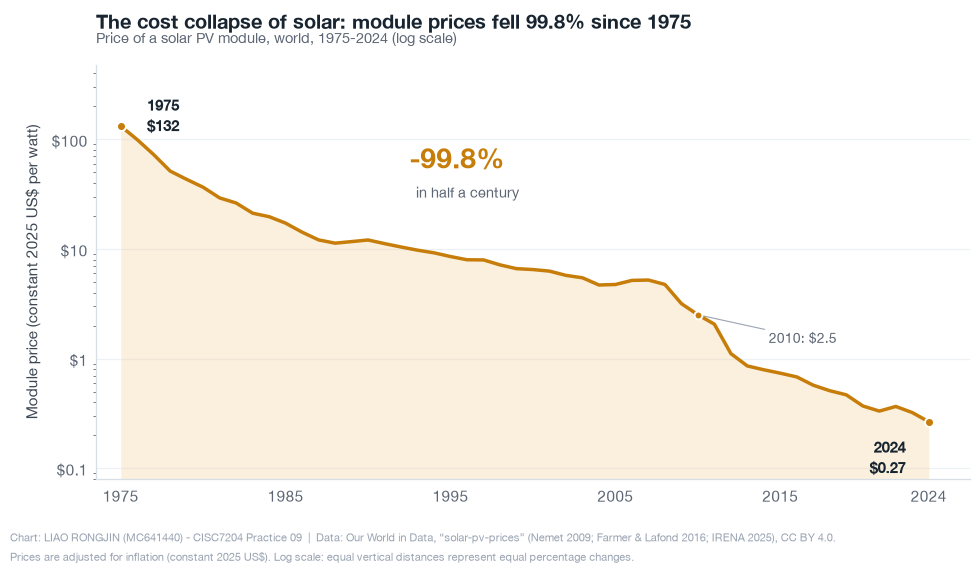

In [4]:
fig, ax = plt.subplots(figsize=(10, 6))
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.tick_params(length=0, pad=6)
ax.yaxis.grid(True, color=GRID, linewidth=0.9)
ax.set_axisbelow(True)

ax.set_yscale("log")
ax.set_ylim(0.08, 480)
ax.set_xlim(1973.5, 2026.5)
ax.set_yticks([0.1, 1, 10, 100])
ax.set_yticklabels(["$0.1", "$1", "$10", "$100"])
ax.set_xticks([1975, 1985, 1995, 2005, 2015, 2024])
ax.set_xticklabels(["1975", "1985", "1995", "2005", "2015", "2024"])

ax.plot(price.Year, price["Solar PV module cost"], color=AMBER_DK, lw=2.5, zorder=5)
ax.fill_between(price.Year, price["Solar PV module cost"], 0.08,
                color=AMBER_LT, alpha=0.30, lw=0, zorder=2)

# anchor points with direct labels
ax.scatter([1975], [p_first["Solar PV module cost"]], s=42, color=AMBER_DK,
           edgecolor=WHITE, linewidth=1.4, zorder=6)
ax.text(1976.6, 165, "1975\n$132", fontsize=11, color=INK, fontweight="bold",
        va="center", ha="left", linespacing=1.15)

r2010 = price[price.Year == 2010].iloc[0]
ax.scatter([2010], [r2010["Solar PV module cost"]], s=32, color=AMBER_DK,
           edgecolor=WHITE, linewidth=1.4, zorder=6)
ax.annotate("2010: $2.5", xy=(2010, float(r2010["Solar PV module cost"])),
            xytext=(2014.3, 1.55), fontsize=10, color=MUTED, ha="left", va="center",
            arrowprops=dict(arrowstyle="-", color=FAINT, lw=0.8, shrinkA=1, shrinkB=3))

ax.scatter([2024], [p_last["Solar PV module cost"]], s=42, color=AMBER_DK,
           edgecolor=WHITE, linewidth=1.4, zorder=6)
ax.text(2022.6, 0.125, "2024\n$0.27", fontsize=11, color=INK, fontweight="bold",
        va="center", ha="right", linespacing=1.15)

ax.text(1992.5, 68, "-99.8%", fontsize=20, fontweight="bold", color=AMBER_DK,
        ha="left", va="center")
ax.text(1992.9, 33, "in half a century", fontsize=10.5, color=MUTED,
        ha="left", va="center")

ax.set_ylabel("Module price (constant 2025 US$ per watt)", fontsize=11,
              color=BODY, labelpad=8)
ax.set_title("The cost collapse of solar: module prices fell 99.8% since 1975",
             fontsize=14.5, fontweight="bold", color=INK, loc="left", pad=26)
ax.text(0.0, 1.045, "Price of a solar PV module, world, 1975-2024 (log scale)",
        transform=ax.transAxes, fontsize=10.5, color=MUTED, ha="left", va="bottom")

fig.text(0.012, 0.008,
         "Chart: LIAO RONGJIN (MC641440) - CISC7204 Practice 09  |  Data: Our World in Data, "
         "\u201csolar-pv-prices\u201d (Nemet 2009; Farmer & Lafond 2016; IRENA 2025), CC BY 4.0.\n"
         "Prices are adjusted for inflation (constant 2025 US$). Log scale: equal vertical "
         "distances represent equal percentage changes.",
         fontsize=8, color=FAINT, ha="left", va="bottom", linespacing=1.5)
fig.subplots_adjust(left=0.098, right=0.972, top=0.845, bottom=0.155)
fig.savefig("figures/fig1_solar_cost_collapse.png", dpi=DPI)
print("saved figures/fig1_solar_cost_collapse.png")


## 5. Figure 2 — the capacity boom

Capacity is plotted on a linear scale because the absolute scale is the message; the slope of the area chart shows the accelerating pace of installations.

saved figures/fig2_solar_capacity_boom.png


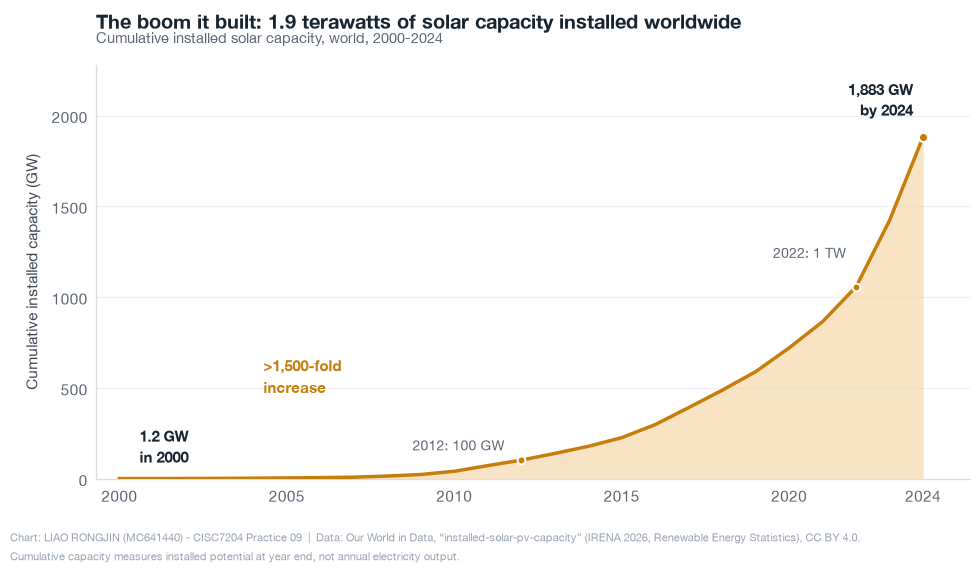

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.tick_params(length=0, pad=6)
ax.yaxis.grid(True, color=GRID, linewidth=0.9)
ax.set_axisbelow(True)

ax.set_xlim(1999.3, 2025.4)
ax.set_ylim(0, 2280)
ax.set_yticks([0, 500, 1000, 1500, 2000])
ax.set_xticks([2000, 2005, 2010, 2015, 2020, 2024])

ax.fill_between(cap.Year, cap.Solar, 0, color=AMBER_LT, alpha=0.55, lw=0, zorder=2)
ax.plot(cap.Year, cap.Solar, color=AMBER_DK, lw=2.5, zorder=5)

ax.scatter([2012], [cap_2012], s=32, color=AMBER_DK, edgecolor=WHITE, linewidth=1.4, zorder=6)
ax.text(2011.5, 185, "2012: 100 GW", fontsize=10, color=MUTED, ha="right", va="center")

ax.scatter([2022], [cap_2022], s=32, color=AMBER_DK, edgecolor=WHITE, linewidth=1.4, zorder=6)
ax.text(2021.7, 1245, "2022: 1 TW", fontsize=10, color=MUTED, ha="right", va="center")

ax.scatter([2024], [cap_2024], s=42, color=AMBER_DK, edgecolor=WHITE, linewidth=1.4, zorder=6)
ax.text(2023.7, 1965, "1,883 GW\nby 2024", fontsize=11, color=INK, fontweight="bold",
        ha="right", va="bottom", linespacing=1.15)

ax.text(2000.6, 62, "1.2 GW\nin 2000", fontsize=11, color=INK, fontweight="bold",
        ha="left", va="bottom", linespacing=1.15)
ax.text(2004.3, 560, ">1,500-fold\nincrease", fontsize=10.5, color=AMBER_DK,
        fontweight="bold", ha="left", va="center", linespacing=1.2)

ax.set_ylabel("Cumulative installed capacity (GW)", fontsize=11, color=BODY, labelpad=8)
ax.set_title("The boom it built: 1.9 terawatts of solar capacity installed worldwide",
             fontsize=14.5, fontweight="bold", color=INK, loc="left", pad=26)
ax.text(0.0, 1.045, "Cumulative installed solar capacity, world, 2000-2024",
        transform=ax.transAxes, fontsize=10.5, color=MUTED, ha="left", va="bottom")

fig.text(0.012, 0.008,
         "Chart: LIAO RONGJIN (MC641440) - CISC7204 Practice 09  |  Data: Our World in Data, "
         "\u201cinstalled-solar-pv-capacity\u201d (IRENA 2026, Renewable Energy Statistics), CC BY 4.0.\n"
         "Cumulative capacity measures installed potential at year end, not annual electricity output.",
         fontsize=8, color=FAINT, ha="left", va="bottom", linespacing=1.5)
fig.subplots_adjust(left=0.098, right=0.972, top=0.845, bottom=0.155)
fig.savefig("figures/fig2_solar_capacity_boom.png", dpi=DPI)
print("saved figures/fig2_solar_capacity_boom.png")


## 6. Summary of findings

Print the three findings and the main limitation of this analysis.

In [6]:
print()
print("KEY FINDINGS")
print("-" * 72)
print(f"1. Module prices fell from ${p_first['Solar PV module cost']:.2f}/W in {int(p_first.Year)} "
      f"to ${p_last['Solar PV module cost']:.2f}/W in {int(p_last.Year)} ({price_change:+.1f}%).")
print(f"2. Global cumulative installed capacity rose from {cap_2000:.1f} GW in 2000 to "
      f"{cap_2024:,.0f} GW in 2024 (x{cap_2024/cap_2000:,.0f}).")
print(f"3. The world passed 1 terawatt of installed capacity in 2022 "
      f"({cap_2022:,.0f} GW) and reached {cap_2024:,.0f} GW by the end of 2024.")
print()
print("LIMITATION: capacity is a stock of installed potential, not electricity actually")
print("generated; cumulative world totals also hide large differences between countries.")



KEY FINDINGS
------------------------------------------------------------------------
1. Module prices fell from $132.38/W in 1975 to $0.27/W in 2024 (-99.8%).
2. Global cumulative installed capacity rose from 1.2 GW in 2000 to 1,883 GW in 2024 (x1,542).
3. The world passed 1 terawatt of installed capacity in 2022 (1,058 GW) and reached 1,883 GW by the end of 2024.

LIMITATION: capacity is a stock of installed potential, not electricity actually
generated; cumulative world totals also hide large differences between countries.
